# P1 — Analyse météo (Open-Meteo, 12 villes, 5 ans)

**Source** : couche silver `silver/meteo/` (Parquet dans Silo) — 525 888 lignes ville × heure UTC, du 01/11/2021 au
31/10/2026, 100 % valides. Valeurs issues de la réanalyse ERA5 (modèle, grille ~9-25 km), pas de stations.

**Adaptation du sujet** : la *visibilité* est absente de l'archive Open-Meteo (100 % vide). La question 2
« corrélation météo / visibilité » est donc traitée comme une **analyse des corrélations entre variables météo**
(température, humidité, pluie, pression, nébulosité, vent).

Agrégations journalières en **date locale** (Europe/Paris).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common.storage import get_storage
from common.silver import read_silver
from common import viz
from p1_meteo import analytics as a

viz.apply_style()
pd.set_option("display.width", 160)
df = read_silver(get_storage(), "silver/meteo/")
day = a.daily(df)
print(f"{len(df):,} heures → {len(day):,} jours ville × date ({day['date'].min():%d/%m/%Y} → {day['date'].max():%d/%m/%Y})")

525,888 heures → 21,912 jours ville × date (01/11/2021 → 31/10/2026)


## Q1 — Périodes météorologiques anormales

**Méthode** : pour chaque ville, la **normale saisonnière** est la température moyenne de chaque jour de l'année
sur les 5 ans, lissée sur ± 7 jours. L'**anomalie** d'un jour = température moyenne − normale ; le **z-score**
la rapporte à la variabilité habituelle de la ville pour ce mois. Un **épisode** = au moins 3 jours consécutifs
avec |z| ≥ 1,5 ; un épisode est dit **national** quand au moins 6 des 12 villes sont simultanément concernées.

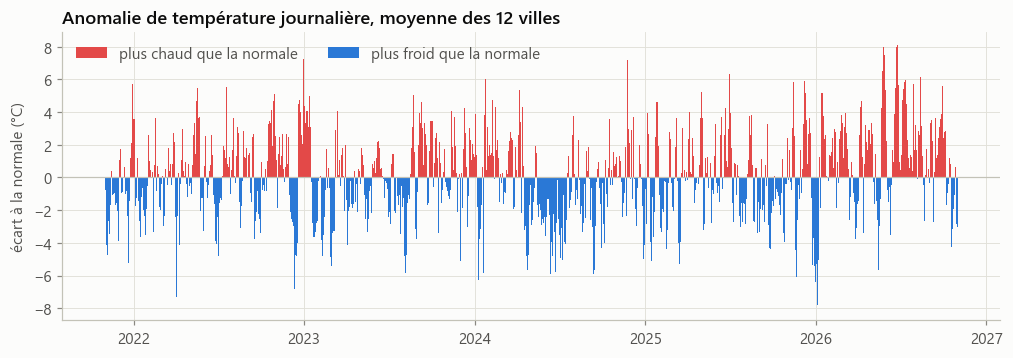

In [2]:
an = a.anomalies(day)
nat = an.groupby("date")["anomalie"].mean()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(nat.index, nat.where(nat > 0, 0), width=1.0, color=viz.WARM, label="plus chaud que la normale")
ax.bar(nat.index, nat.where(nat < 0, 0), width=1.0, color=viz.COOL, label="plus froid que la normale")
ax.axhline(0, color=viz.AXIS, lw=0.8)
ax.set_title("Anomalie de température journalière, moyenne des 12 villes")
ax.set_ylabel("écart à la normale (°C)")
ax.legend(loc="upper left", ncols=2)
plt.show()

In [3]:
ep = a.episodes(an)
nat_ep = a.national_episodes(ep)
print(f"{len(ep)} épisodes ville (≥ 3 jours, |z| ≥ 1,5) : {ep['type'].value_counts().to_dict()} ; "
      f"{int((an['z'].abs() > 3).sum())} jours ville avec |z| > 3")
print("\nÉpisodes NATIONAUX (≥ 6 villes simultanément) :")
display(nat_ep.assign(debut=nat_ep['debut'].dt.strftime('%d/%m/%Y'), fin=nat_ep['fin'].dt.strftime('%d/%m/%Y')).head(8))
print("Épisodes les plus longs par ville :")
display(ep.head(6).assign(debut=ep['debut'].dt.strftime('%d/%m/%Y'), fin=ep['fin'].dt.strftime('%d/%m/%Y')))

349 épisodes ville (≥ 3 jours, |z| ≥ 1,5) : {'froid': 177, 'chaud': 172} ; 43 jours ville avec |z| > 3

Épisodes NATIONAUX (≥ 6 villes simultanément) :


,type,debut,fin,jours,villes_max
0,chaud,23/05/2026,30/05/2026,8,12
1,chaud,06/07/2026,13/07/2026,8,10
2,chaud,21/06/2026,27/06/2026,7,11
3,froid,04/08/2023,08/08/2023,5,12
4,froid,21/04/2024,25/04/2024,5,12
5,froid,26/02/2023,02/03/2023,5,12
6,froid,13/03/2025,17/03/2025,5,11
7,chaud,26/10/2022,29/10/2022,4,10


Épisodes les plus longs par ville :


,ville_id,debut,fin,jours,type,anomalie_moy_c,z_max
0,strasbourg,19/06/2026,28/06/2026,10,chaud,6.8,3.1
1,rouen,09/12/2022,18/12/2022,10,froid,-7.2,2.6
2,paris,06/07/2026,15/07/2026,10,chaud,6.5,2.3
3,nantes,22/05/2026,30/05/2026,9,chaud,8.7,3.4
4,rouen,22/05/2026,30/05/2026,9,chaud,8.3,3.1
5,rennes,06/07/2026,14/07/2026,9,chaud,7.0,2.9


**Conclusion Q1.**
- On détecte **349 épisodes** ville (172 chauds, 177 froids) et **43 jours** vraiment exceptionnels (|z| > 3) :
  les anomalies chaudes et froides sont aussi fréquentes, mais les **épisodes nationaux les plus longs sont chauds**.
- Les trois plus longs épisodes nationaux sont **tous en 2026** : du 23 au 30 mai (les 12 villes, jusqu'à
  +8,7 °C à Nantes), du 21 au 27 juin et du 6 au 13 juillet — une succession de vagues de chaleur précoces.
- Côté froid, les épisodes nationaux sont plus courts (5 jours) ; le plus marqué localement est la **vague de froid
  de décembre 2022** (Rouen, 10 jours à −7 °C sous la normale ; Strasbourg à −11 °C le 17/12/2022).

## Q2 — Corrélations entre variables météo *(remplace « météo / visibilité »)*

**Méthode** : corrélations sur les 525 888 heures, **Pearson** (relation linéaire) et **Spearman** (relation
monotone, robuste aux valeurs extrêmes et adaptée à la pluie, très asymétrique). On présente Spearman.

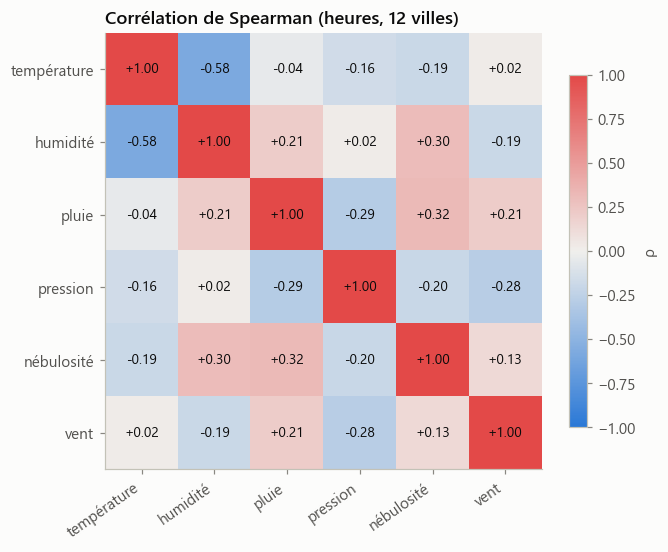

Pearson, pour comparaison :


,temperature_c,humidite_pct,precipitation_mm,pression_hpa,nebulosite_pct,vent_ms
temperature_c,1.00,-0.64,-0.01,-0.13,-0.18,0.02
humidite_pct,-0.64,1.00,0.14,-0.01,0.28,-0.14
precipitation_mm,-0.01,0.14,1.00,-0.19,0.17,0.11
pression_hpa,-0.13,-0.01,-0.19,1.00,-0.20,-0.32
nebulosite_pct,-0.18,0.28,0.17,-0.20,1.00,0.13
vent_ms,0.02,-0.14,0.11,-0.32,0.13,1.00


In [4]:
c = a.correlations(df)
labels = ["température", "humidité", "pluie", "pression", "nébulosité", "vent"]
m = c["spearman"].values
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(m, cmap=viz.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(6), labels, rotation=35, ha="right"); ax.set_yticks(range(6), labels)
ax.grid(False)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{m[i, j]:+.2f}", ha="center", va="center", fontsize=9, color=viz.INK)
ax.set_title("Corrélation de Spearman (heures, 12 villes)")
fig.colorbar(im, ax=ax, shrink=0.8, label="ρ")
plt.show()
print("Pearson, pour comparaison :"); display(c["pearson"])

**Conclusion Q2.**
- La relation la plus forte est **température ↔ humidité (ρ = −0,58)** : l'air chaud de l'après-midi est plus sec,
  l'air frais de la nuit plus humide (cycle diurne).
- La **pluie** va avec la **nébulosité (+0,32)** et l'**humidité (+0,21)**, et avec une **pression basse (−0,29)** :
  la signature des dépressions, qui apportent aussi le **vent** (pression ↔ vent −0,28, pluie ↔ vent +0,21).
- Les corrélations restent modérées (|ρ| < 0,6) : aucune variable n'en remplace une autre, ce qui justifie de les
  garder toutes pour l'analyse croisée et le modèle ML. *Limite* : sans visibilité, on ne peut pas mesurer l'effet du
  brouillard ; l'humidité proche de 100 % en est le meilleur indicateur disponible.

## Q3 — Évolution saisonnière de la température

**Méthode** : température moyenne par ville et par mois calendaire (climatologie des 5 ans) ; pour comparer les
années sans biais, on utilise des **années d'étude complètes de novembre à octobre** (les années civiles 2021 et
2026 sont incomplètes).

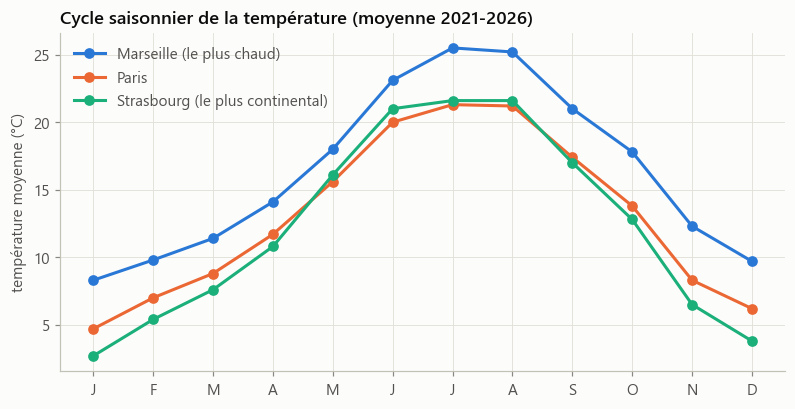

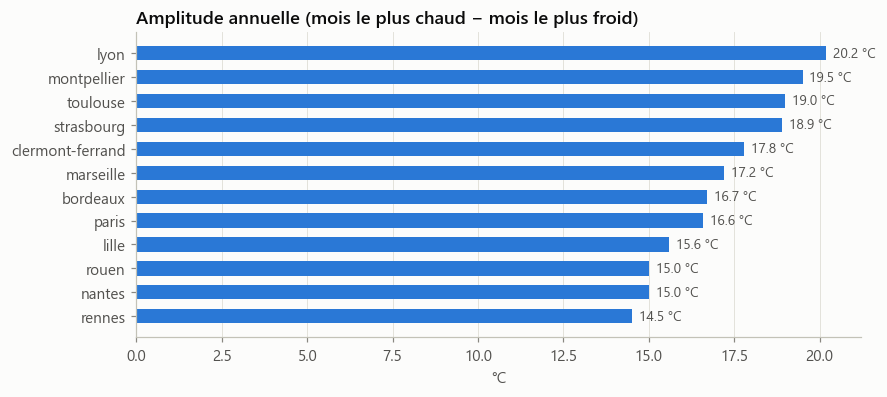

In [5]:
cl = a.climatology(day)
mois = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
fig, ax = plt.subplots(figsize=(8.5, 4))
for ville, nom in (("marseille", "Marseille (le plus chaud)"), ("paris", "Paris"),
                   ("strasbourg", "Strasbourg (le plus continental)")):
    ax.plot(range(1, 13), cl.loc[ville, list(range(1, 13))], marker="o", label=nom)
ax.set_xticks(range(1, 13), mois); ax.set_ylabel("température moyenne (°C)")
ax.set_title("Cycle saisonnier de la température (moyenne 2021-2026)")
ax.legend(); plt.show()

amp = cl["amplitude"].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.barh(amp.index, amp.values, color=viz.BLUE, height=0.6)
for y, v in enumerate(amp.values):
    ax.text(v + 0.2, y, f"{v:.1f} °C", va="center", fontsize=9, color=viz.INK_2)
ax.set_title("Amplitude annuelle (mois le plus chaud − mois le plus froid)"); ax.set_xlabel("°C")
ax.grid(axis="y", visible=False); plt.show()

periode,2021-22,2022-23,2023-24,2024-25,2025-26
ville_id,,,,,
bordeaux,14.80,14.70,14.1,14.80,16.00
clermont-ferrand,12.30,12.50,11.9,12.00,13.60
lille,12.00,11.80,11.9,11.80,12.90
lyon,13.30,13.70,12.9,13.00,14.60
marseille,16.20,16.20,16.0,16.40,17.20
montpellier,16.30,16.10,15.8,16.10,17.20
nantes,13.90,13.60,13.0,13.60,15.10
paris,12.80,12.80,12.5,12.80,14.40
rennes,13.10,12.80,12.3,12.90,14.20


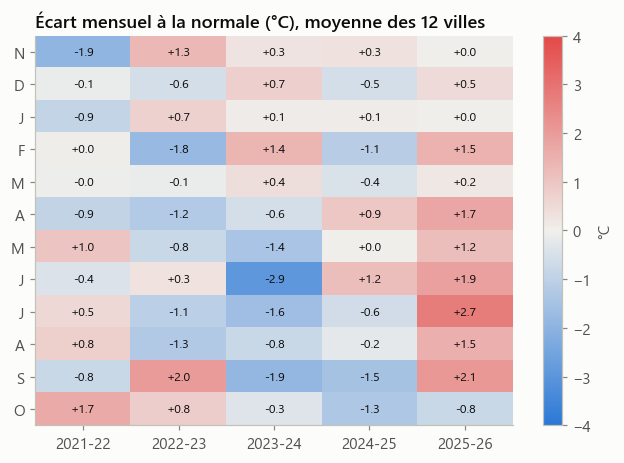

In [6]:
y = a.study_years(day)
tab = y.pivot(index="ville_id", columns="periode", values="t_moy").round(1)
tab.loc["moyenne 12 villes"] = tab.mean().round(2)
display(tab)
nat_month = day.assign(ym=day["date"].dt.to_period("M")).groupby("ym")["t_moy"].mean()
clim_nat = nat_month.groupby(nat_month.index.month).mean()
anom = (nat_month - clim_nat.reindex(nat_month.index.month).values).to_frame("a")
anom["annee"] = [p.year if p.month >= 11 else p.year - 1 for p in anom.index]
anom["mois"] = anom.index.month
order = [11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
grid = anom.pivot(index="mois", columns="annee", values="a").reindex(order)
fig, ax = plt.subplots(figsize=(7, 4.6))
im = ax.imshow(grid.values, cmap=viz.DIVERGING, vmin=-4, vmax=4, aspect="auto")
ax.set_yticks(range(12), ["N", "D", "J", "F", "M", "A", "M", "J", "J", "A", "S", "O"])
ax.set_xticks(range(grid.shape[1]), [f"{c}-{str(c + 1)[-2:]}" for c in grid.columns]); ax.grid(False)
for i in range(12):
    for j in range(grid.shape[1]):
        if not np.isnan(grid.values[i, j]):
            ax.text(j, i, f"{grid.values[i, j]:+.1f}", ha="center", va="center", fontsize=8, color=viz.INK)
ax.set_title("Écart mensuel à la normale (°C), moyenne des 12 villes")
fig.colorbar(im, ax=ax, label="°C"); plt.show()

**Conclusion Q3.**
- Le cycle saisonnier est net partout, avec un minimum en **janvier** et un maximum en **juillet-août**. Marseille
  et Montpellier sont les plus douces (≈ 8 °C en janvier, ≈ 26 °C en juillet).
- L'**amplitude annuelle** sépare les climats : **océanique** à l'ouest (Rennes 14,5 °C, Nantes et Rouen 15,0 °C)
  contre **continental** à l'est et dans les vallées (**Lyon 20,2 °C**, Montpellier 19,5 °C, Strasbourg 18,9 °C).
- Sur des années comparables (novembre → octobre), les quatre premières sont proches (13,2 à 13,7 °C), puis
  **2025-26 est nettement la plus chaude (14,8 °C, ≈ +1,3 °C)**, et ce **dans les 12 villes**. La heatmap montre
  que cet écart vient surtout du printemps et de l'été 2026.

## Q4 — Jours extrêmes (chaleur, froid, vent, pluie)

**Méthode** : seuils **relatifs au climat de chaque ville** — un jour est extrême s'il dépasse le percentile 99 de
sa ville sur 5 ans (T max, vent max, cumul de pluie) ou passe sous le percentile 1 (T min). 35 °C à Marseille et
à Lille n'ont pas la même rareté : un seuil unique ne ferait ressortir que le Sud.

In [7]:
ex = a.extreme_days(day)
print("Jours ville extrêmes par type :", ex["type"].value_counts().to_dict())
top = a.top_extremes(day, 5)
for nom, unite in (("chaleur", "°C (T max)"), ("froid", "°C (T min)"), ("vent", "m/s (vent horaire max)"),
                   ("pluie", "mm (cumul du jour)")):
    print(f"\nRecords — {nom} [{unite}]")
    display(top[nom].assign(date=top[nom]["date"].dt.strftime("%d/%m/%Y"), valeur=top[nom]["valeur"].round(1)))

Jours ville extrêmes par type : {'froid': 235, 'chaleur': 232, 'vent': 231, 'pluie': 228}

Records — chaleur [°C (T max)]


,ville_id,date,valeur
0,montpellier,08/07/2026,41.9
1,bordeaux,11/08/2025,41.7
2,bordeaux,23/06/2026,41.4
3,bordeaux,24/06/2026,41.2
4,toulouse,11/08/2025,41.2



Records — froid [°C (T min)]


,ville_id,date,valeur
0,strasbourg,17/12/2022,-11.0
1,strasbourg,18/12/2022,-9.1
2,strasbourg,16/12/2022,-8.1
3,toulouse,06/01/2026,-8.1
4,clermont-ferrand,07/01/2026,-7.4



Records — vent [m/s (vent horaire max)]


,ville_id,date,valeur
0,lille,18/02/2022,19.4
1,marseille,02/04/2022,15.7
2,toulouse,12/04/2022,15.6
3,lille,02/11/2023,15.6
4,lille,20/02/2022,15.4



Records — pluie [mm (cumul du jour)]


,ville_id,date,valeur
0,marseille,20/10/2026,180.0
1,montpellier,14/09/2022,116.2
2,montpellier,04/05/2026,78.0
3,nantes,09/10/2024,73.6
4,montpellier,30/09/2026,73.4


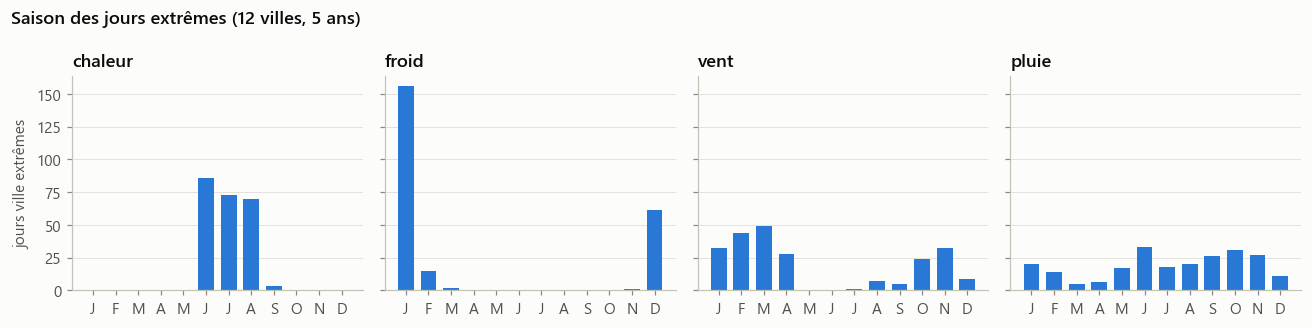

Jours où ≥ 6 villes sont en chaleur extrême : 18/06/2022, 18/07/2022, 19/07/2022, 30/06/2025, 01/07/2025, 21/06/2026, 22/06/2026, 23/06/2026, 24/06/2026, 25/06/2026, 29/07/2026, 13/08/2026


In [8]:
per_month = ex.assign(m=ex["date"].dt.month).groupby(["type", "m"]).size().unstack(0).reindex(range(1, 13)).fillna(0)
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for ax, nom in zip(axes, ["chaleur", "froid", "vent", "pluie"]):
    ax.bar(range(1, 13), per_month[nom], color=viz.BLUE, width=0.7)
    ax.set_title(nom); ax.set_xticks(range(1, 13), mois); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("jours ville extrêmes")
fig.suptitle("Saison des jours extrêmes (12 villes, 5 ans)", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout(); plt.show()
simult = ex[ex["type"] == "chaleur"].groupby("date")["ville_id"].nunique()
print("Jours où ≥ 6 villes sont en chaleur extrême :", ", ".join(simult[simult >= 6].index.strftime("%d/%m/%Y")))

**Conclusion Q4.**
- **Chaleur** : uniquement de **juin à septembre** ; record à **Montpellier, 41,9 °C le 08/07/2026**, puis Bordeaux
  (41,7 °C le 11/08/2025). Les 12 jours où au moins 6 villes sont simultanément en chaleur extrême correspondent à
  des vagues de chaleur nationales : **juin et juillet 2022**, **fin juin - début juillet 2025** et surtout
  **juin 2026** (5 jours consécutifs, du 21 au 25).
- **Froid** : record à **Strasbourg, −11 °C le 17/12/2022**, au cœur de la vague de froid de décembre 2022.
- **Vent** : record à **Lille le 18/02/2022 (19,4 m/s de vent moyen horaire, ≈ 70 km/h)** — la tempête Eunice ;
  les jours de vent extrême sont surtout hivernaux et printaniers.
- **Pluie** : les jours de pluie extrême existent toute l'année, avec un pic en **juin (orages)** et un second en
  **automne**. Les records absolus sont sur l'arc méditerranéen (**Marseille 180 mm le 20/10/2026**, Montpellier
  116 mm le 14/09/2022) : des **épisodes méditerranéens** d'automne, très concentrés, alors que le Sud est par
  ailleurs la zone la plus sèche en cumul annuel.

## Synthèse P1

| Constat | Chiffre clé |
|---|---|
| Ville la plus chaude / la plus fraîche | Marseille et Montpellier ≈ 16,4 °C / Lille, Rouen, Strasbourg ≈ 12 °C |
| Climat le plus continental | Lyon (amplitude annuelle 20,2 °C) |
| Année la plus chaude | 2025-26 : 14,8 °C, ≈ +1,3 °C sur les 4 précédentes, dans les 12 villes |
| Année la plus sèche / la plus pluvieuse | 2021-22 (663 mm) / 2023-24 (1 128 mm) |
| Plus longs épisodes nationaux | trois vagues de chaleur en mai-juillet 2026 (7-8 jours, jusqu'à 12 villes) |
| Records | 41,9 °C Montpellier · −11 °C Strasbourg · 19,4 m/s Lille (Eunice) · 180 mm Marseille |

*Limites* : données modélisées (ERA5) et non mesurées ; la réanalyse lisse les extrêmes locaux et surestime les
petites pluies ; pas de visibilité ; 5 ans ne suffisent pas pour parler de tendance climatique (on compare des
années, on ne calcule pas de tendance).